In [1]:
import logging
logging.captureWarnings(True)

In [2]:
import numpy as np
import networkx as nx

In [3]:
from multifractal_networks.mfng import MultifractalNetworkGenerator
from multifractal_networks.mfnf import MultifractalNetworkFitter
from multifractal_networks.utils.motifs import MotifGenerator

# Load Network

In [4]:
filename = './test_networks/human_proteins_network_figeys.txt'
G = nx.read_edgelist(filename)

In [5]:
len(G)

2239

In [6]:
2 * G.number_of_edges() / G.number_of_nodes()

5.74542206342117

In [7]:
for m_size in [2,3,5,6,7]:
    print(m_size,' k_max: ',int(np.log(len(G))/np.log(m_size))+1)

2  k_max:  12
3  k_max:  8
5  k_max:  5
6  k_max:  5
7  k_max:  4


# Init Fitter

In [22]:
mfnf = MultifractalNetworkFitter(
    G,                                   
    motifs = [
        {'name': 'four_chain', 'matrix': np.array([[0, 1, 0, 0],[1, 0, 1, 0],[0, 1, 0, 1],[0, 0, 1, 0]])},
        {'name': 'three_loop_out', 'matrix': np.array([[0, 1, 1, 1],[1, 0, 1, 0],[1, 1, 0, 0],[1, 0, 0, 0]])},
        {'name': 'four_loop', 'matrix': np.array([[0, 1, 0, 1],[1, 0, 1, 0],[0, 1, 0, 1],[1, 0, 1, 0]])},
        {'name': 'four_semi_clique', 'matrix': np.array([[0, 1, 1, 1],[1, 0, 0, 1],[1, 0, 0, 1],[1, 1, 1, 0]])},
    ],
    sampling_ratios = {
        3: 0.01,
        4: 0.0001
    },
    motif_analyzer_args = {'exact': True, 'bootstrap_iters': None, 'ci': None},
    population_size = 100,
    weights = {
        'rho':9,
        'deg_nn':9,
        'motifs':1,
        'edge':9
    }
)

Measuring graph properties...
Degree distribution...
Degree correlations...
Motifs...
Checking compatibility with 4 user-provided motifs.
Adding custom motif 'four_chain'.
Adding custom motif 'three_loop_out'.
Adding custom motif 'four_loop'.
Adding custom motif 'four_semi_clique'.
Counting motifs of size 3... grab a tea or watch a movie, this might take a while.
Motif counting finished in 0:00:00.774569
Counting motifs of size 4... grab a tea or watch a movie, this might take a while.
Motif counting finished in 0:01:05.468273


In [23]:
mfnf.motifs

[{'name': 'edge',
  'matrix': array([[0, 1],
         [1, 0]]),
  'size': 2,
  'count': 6432},
 {'name': 'wedge',
  'matrix': array([[0, 1, 1],
         [1, 0, 0],
         [1, 0, 0]]),
  'size': 3,
  'count': 351088},
 {'name': 'triangle',
  'matrix': array([[0, 1, 1],
         [1, 0, 1],
         [1, 1, 0]]),
  'size': 3,
  'count': 897},
 {'name': 'three_star',
  'matrix': array([[0, 1, 1, 1],
         [1, 0, 0, 0],
         [1, 0, 0, 0],
         [1, 0, 0, 0]]),
  'size': 4,
  'count': 21162272},
 {'name': 'four_clique',
  'matrix': array([[0, 1, 1, 1],
         [1, 0, 1, 1],
         [1, 1, 0, 1],
         [1, 1, 1, 0]]),
  'size': 4,
  'count': 99},
 {'name': 'four_chain',
  'matrix': array([[0, 1, 0, 0],
         [1, 0, 1, 0],
         [0, 1, 0, 1],
         [0, 0, 1, 0]]),
  'size': 4,
  'count': 3567418},
 {'name': 'three_loop_out',
  'matrix': array([[0, 1, 1, 1],
         [1, 0, 1, 0],
         [1, 1, 0, 0],
         [1, 0, 0, 0]]),
  'size': 4,
  'count': 173524},
 {'name':

# Grid Search

In [27]:
mfnf.population_size = 300

In [28]:
mfnf.find_m_k_P_l(
    m_k_dict = [{'m': 2,  'k': [1,12]},
                {'m': 3,  'k': [1,8]},
                {'m': 5,  'k': [1,5]},
                {'m': 6,  'k': [1,5]},
                {'m': 7,  'k': [1,4]}],
    n_trials = None,
    P_init = 'm x m',
    l_init = 'dirichlet',
    verbose = False,
    grid_search = True,
    optimize_for = 'kl_energy'
)

[I 2025-03-04 17:03:27,086] A new study created in memory with name: no-name-fbba2f11-e26c-4069-aa1b-e222168e8542


Grid Search requires 11 trials...


[I 2025-03-04 17:03:59,772] Trial 0 finished with value: 8.957382187025242 and parameters: {'m': 2, 'k': 5}. Best is trial 0 with value: 8.957382187025242.
[I 2025-03-04 17:06:51,966] Trial 1 finished with value: 8.614662731860301 and parameters: {'m': 2, 'k': 10}. Best is trial 1 with value: 8.614662731860301.
[I 2025-03-04 17:07:29,829] Trial 2 finished with value: 9.90086873312242 and parameters: {'m': 2, 'k': 3}. Best is trial 1 with value: 8.614662731860301.
[I 2025-03-04 17:14:53,704] Trial 3 finished with value: 8.843024009475588 and parameters: {'m': 2, 'k': 11}. Best is trial 1 with value: 8.614662731860301.
[I 2025-03-04 17:15:36,678] Trial 4 finished with value: 8.861752276700448 and parameters: {'m': 2, 'k': 7}. Best is trial 1 with value: 8.614662731860301.
[I 2025-03-04 17:16:12,028] Trial 5 finished with value: 12.841480321471579 and parameters: {'m': 2, 'k': 2}. Best is trial 1 with value: 8.614662731860301.
[I 2025-03-04 17:17:05,309] Trial 6 finished with value: 8.373

Grid Search requires 7 trials...


[I 2025-03-04 17:34:48,289] Trial 0 finished with value: 7.118099683252232 and parameters: {'m': 3, 'k': 7}. Best is trial 0 with value: 7.118099683252232.
[I 2025-03-04 17:36:02,959] Trial 1 finished with value: 7.202708530860262 and parameters: {'m': 3, 'k': 3}. Best is trial 0 with value: 7.118099683252232.
[I 2025-03-04 17:37:10,211] Trial 2 finished with value: 7.531778322820408 and parameters: {'m': 3, 'k': 2}. Best is trial 0 with value: 7.118099683252232.
[I 2025-03-04 17:38:13,202] Trial 3 finished with value: 7.448135087365072 and parameters: {'m': 3, 'k': 4}. Best is trial 0 with value: 7.118099683252232.
[I 2025-03-04 17:38:55,126] Trial 4 finished with value: 20.833891710005272 and parameters: {'m': 3, 'k': 1}. Best is trial 0 with value: 7.118099683252232.
[I 2025-03-04 17:42:18,046] Trial 5 finished with value: 7.602046880287721 and parameters: {'m': 3, 'k': 6}. Best is trial 0 with value: 7.118099683252232.
[I 2025-03-04 17:43:45,385] Trial 6 finished with value: 7.5289

Grid Search requires 4 trials...


... (2 outputs left out)

[I 2025-03-04 18:08:00,582] Trial 0 finished with value: 6.682346026776742 and parameters: {'m': 6, 'k': 3}. Best is trial 0 with value: 6.682346026776742.
[I 2025-03-04 18:38:47,368] Trial 1 finished with value: 6.797608868943327 and parameters: {'m': 6, 'k': 4}. Best is trial 0 with value: 6.682346026776742.
[I 2025-03-04 18:42:44,758] Trial 2 finished with value: 6.241998224935516 and parameters: {'m': 6, 'k': 2}. Best is trial 2 with value: 6.241998224935516.
[I 2025-03-04 18:44:55,094] Trial 3 finished with value: 12.991309173811903 and parameters: {'m': 6, 'k': 1}. Best is trial 2 with value: 6.241998224935516.
[I 2025-03-04 18:44:55,097] A new study created in memory with name: no-name-63a5e1dd-7719-4216-851f-a504b14088c7


Grid Search requires 3 trials...


[I 2025-03-04 18:56:12,386] Trial 0 finished with value: 6.014285971730482 and parameters: {'m': 7, 'k': 3}. Best is trial 0 with value: 6.014285971730482.
[I 2025-03-04 19:00:28,767] Trial 1 finished with value: 5.152177388379129 and parameters: {'m': 7, 'k': 2}. Best is trial 1 with value: 5.152177388379129.
[I 2025-03-04 19:02:39,169] Trial 2 finished with value: 15.313614534804296 and parameters: {'m': 7, 'k': 1}. Best is trial 1 with value: 5.152177388379129.


Best parameters:  {'m': 7, 'k': 2}
Best energy:  11.212339874750947
Best KL-divergence:  0.07157689633700279
Best KLD augumented energy: 5.152177388379129
Best P matrix:
 [[2.81662682e-04 3.27111148e-02 1.66622532e-01 2.06769755e-01
  2.24401741e-01 4.79458046e-01 9.68485218e-01]
 [3.27111148e-02 1.31368069e-01 3.22445659e-01 9.06107416e-01
  1.27400487e-02 5.24132403e-03 5.50391776e-01]
 [1.66622532e-01 3.22445659e-01 5.90522065e-02 5.79741098e-03
  4.83390600e-02 3.97796380e-01 5.78278174e-01]
 [2.06769755e-01 9.06107416e-01 5.79741098e-03 7.79761948e-01
  2.42214708e-01 6.98240665e-01 4.98735098e-01]
 [2.24401741e-01 1.27400487e-02 4.83390600e-02 2.42214708e-01
  5.04591321e-03 4.77834851e-01 7.47622453e-02]
 [4.79458046e-01 5.24132403e-03 3.97796380e-01 6.98240665e-01
  4.77834851e-01 9.78187740e-01 8.99205289e-01]
 [9.68485218e-01 5.50391776e-01 5.78278174e-01 4.98735098e-01
  7.47622453e-02 8.99205289e-01 6.43469192e-01]]
Best l vector:
 [0.82615455 0.0659541  0.05074794 0.034291

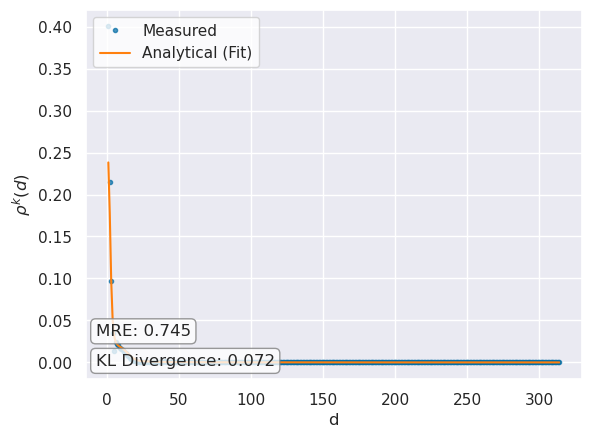

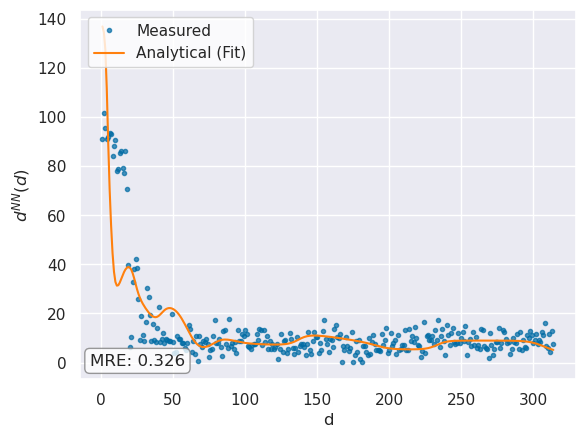

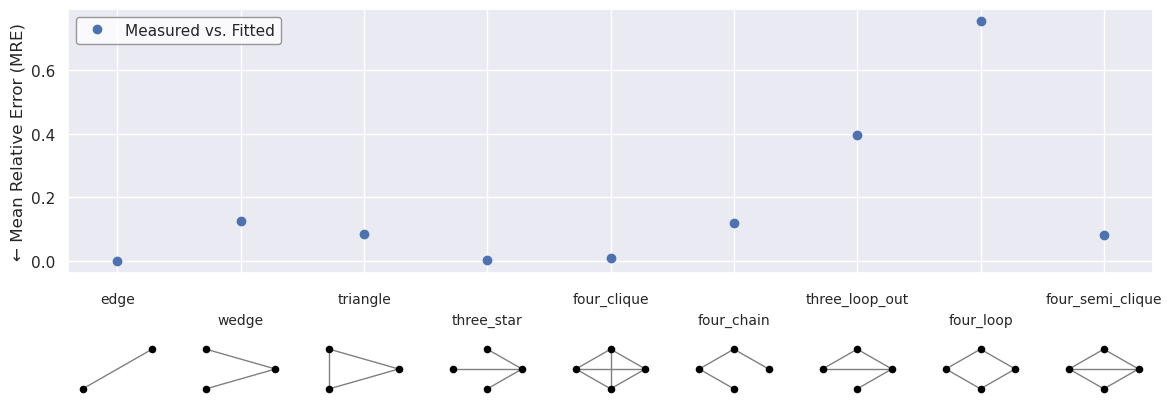

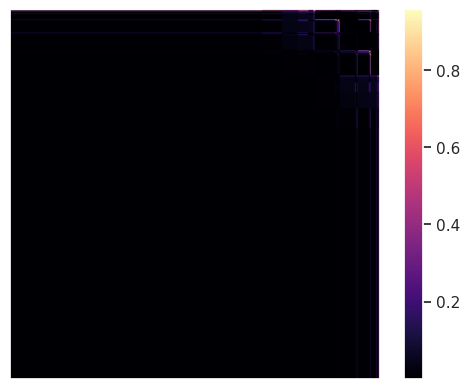

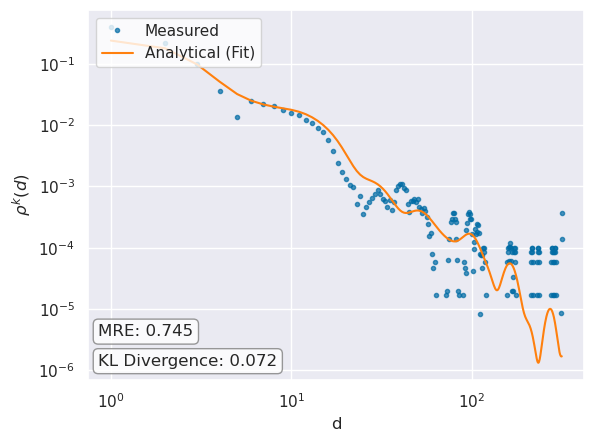

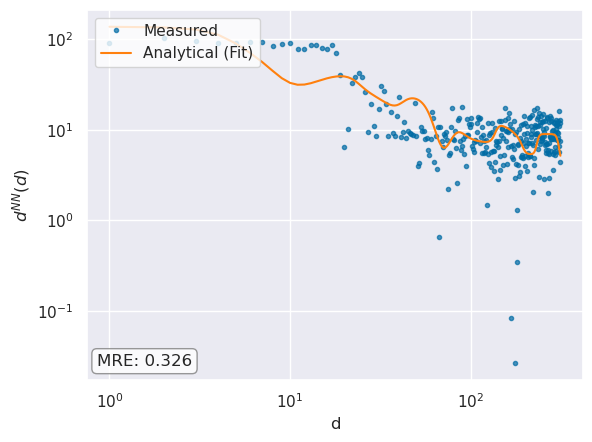

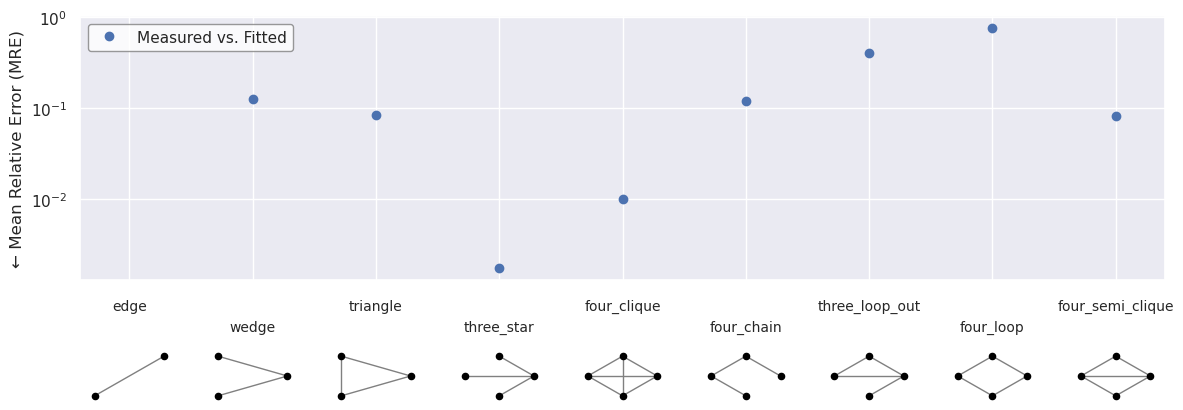

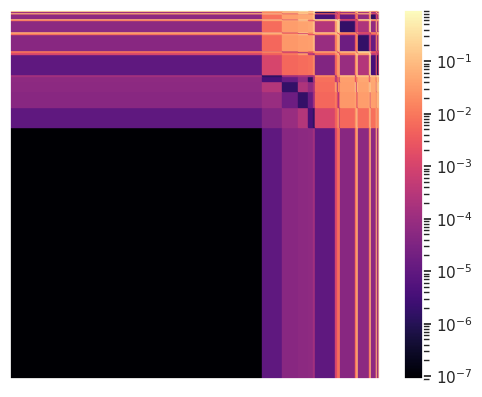

In [29]:
mfnf.plot_P_l_result(
    log_scale = False,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    #filename = "figures/human_proteins_network_plot.pdf"
)
mfnf.plot_P_l_result(
    log_scale = True,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    #filename = "figures/human_proteins_network_log_plot.pdf"
)

# Bootstrapping Stability

In [ ]:
mfnf.bootstrap_P_l_stability(
    P_init = 'm x m',
    l_init = 'dirichlet',
    verbose = True,
    resample_size = mfnf.population_size,
    ci = 0.95,
    medoid = 'median'
)

Gathering statistics (30 runs)...


  3%|▎         | 1/30 [04:58<2:24:21, 298.66s/it]

In [36]:
mfnf.motifs

[{'name': 'edge',
  'matrix': array([[0, 1],
         [1, 0]]),
  'size': 2,
  'count': 6432,
  'expected_count': 6435.0,
  'MRE': 0.0012430085596860417,
  'expected_count_ci_low': 6374.125,
  'expected_count_ci_high': 6694.0,
  'MRE_ci_low': 0.0,
  'MRE_ci_high': 0.039139527935464595},
 {'name': 'wedge',
  'matrix': array([[0, 1, 1],
         [1, 0, 0],
         [1, 0, 0]]),
  'size': 3,
  'count': 351088,
  'expected_count': 311167.0,
  'MRE': 0.11370653511370368,
  'expected_count_ci_low': 255870.0,
  'expected_count_ci_high': 360636.0,
  'MRE_ci_low': 0.00274468597212835,
  'MRE_ci_high': 0.27120835801850246},
 {'name': 'triangle',
  'matrix': array([[0, 1, 1],
         [1, 0, 1],
         [1, 1, 0]]),
  'size': 3,
  'count': 897,
  'expected_count': 1191.0,
  'MRE': 0.24685138539042822,
  'expected_count_ci_low': 769.0,
  'expected_count_ci_high': 1641.4999999999986,
  'MRE_ci_low': 0.023939064200217627,
  'MRE_ci_high': 0.45336612489307054},
 {'name': 'three_star',
  'matrix': ar

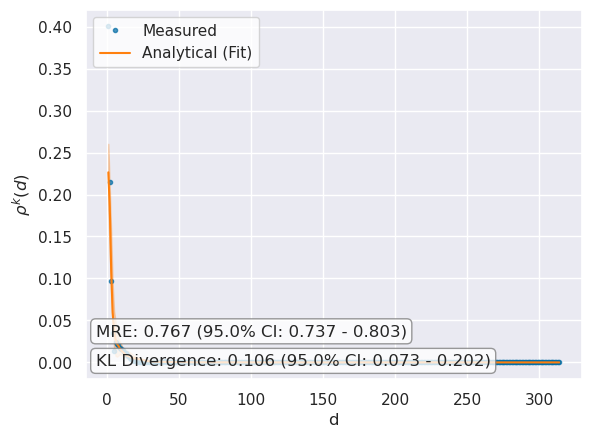

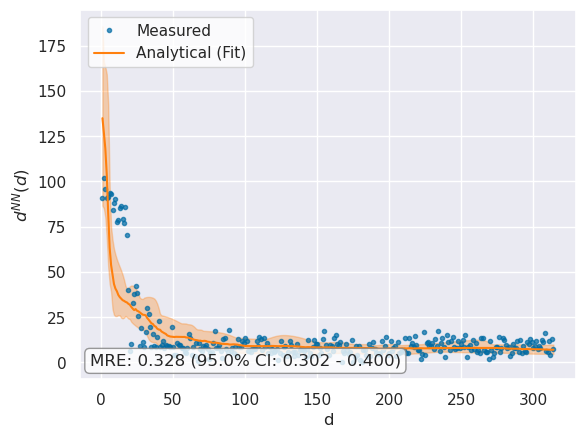

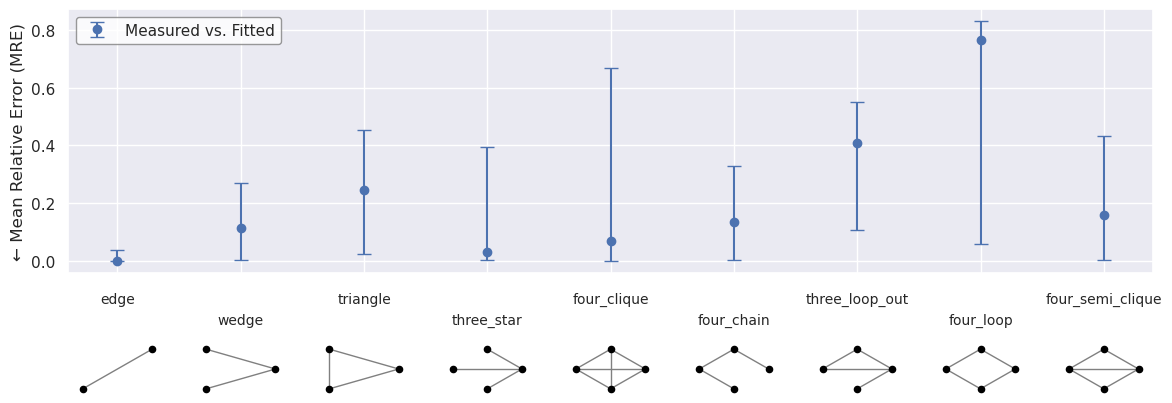

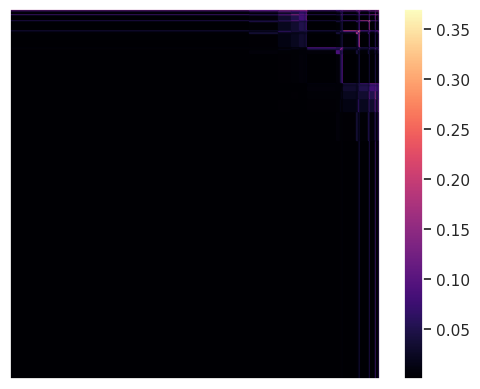

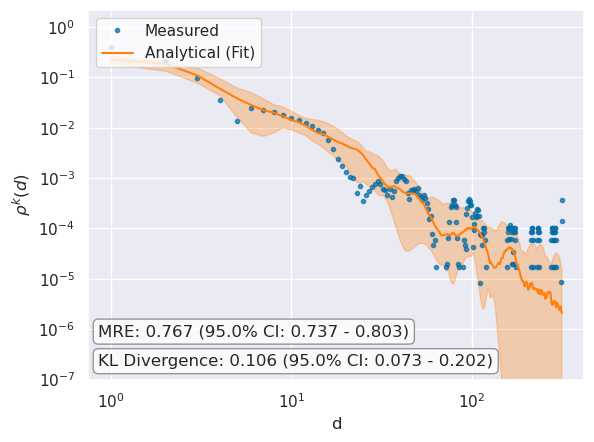

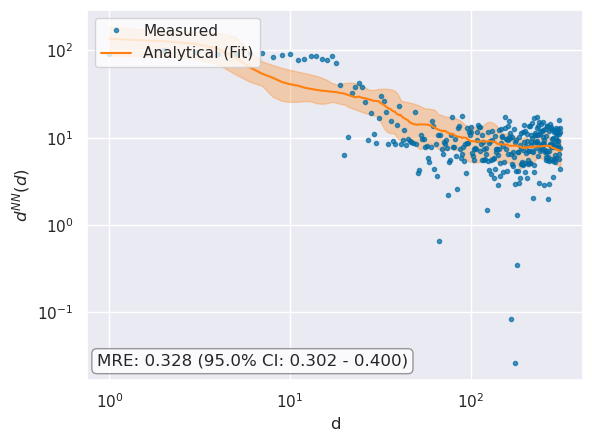

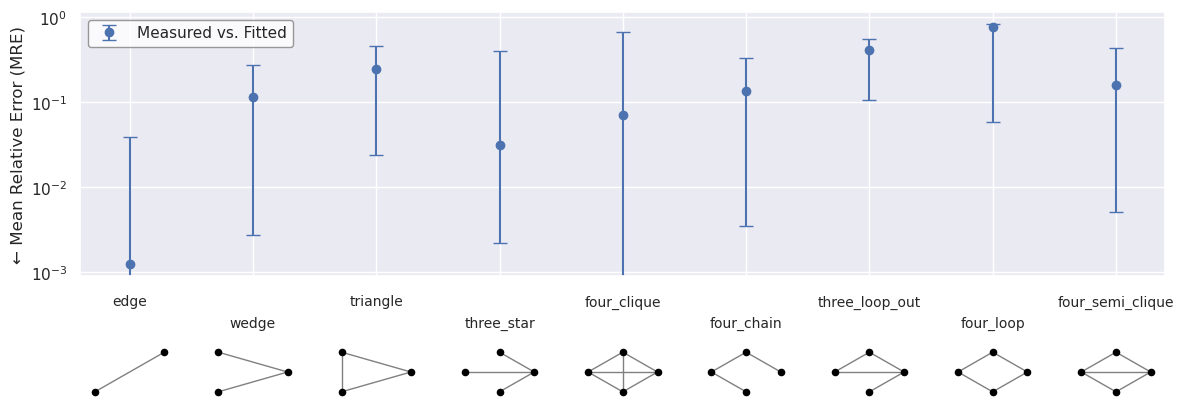

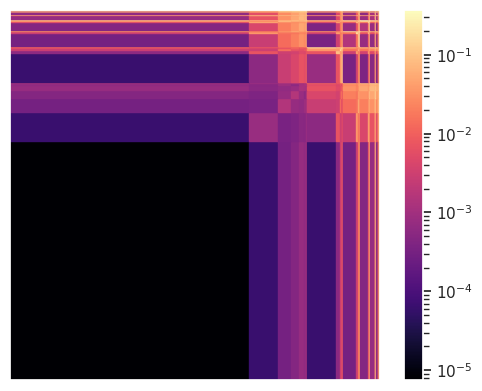

In [37]:
mfnf.plot_P_l_result(
    log_scale = False,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    filename = "figures/human_proteins_network_figeys_plot.pdf"
)
mfnf.plot_P_l_result(
    log_scale = True,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    ylim=[1e-7,0],
    filename = "figures/human_proteins_network_figeys_log_plot.pdf"
)

In [38]:
import pickle
with open('./test_networks/human_proteins_network_figeys_mfnf.pkl', 'wb') as f:
    pickle.dump(mfnf, f)

# Generate Variants

Initializing...
0.0006923675537109375
Calculating betweenness...
Done.
Calculating node positions...
Done.


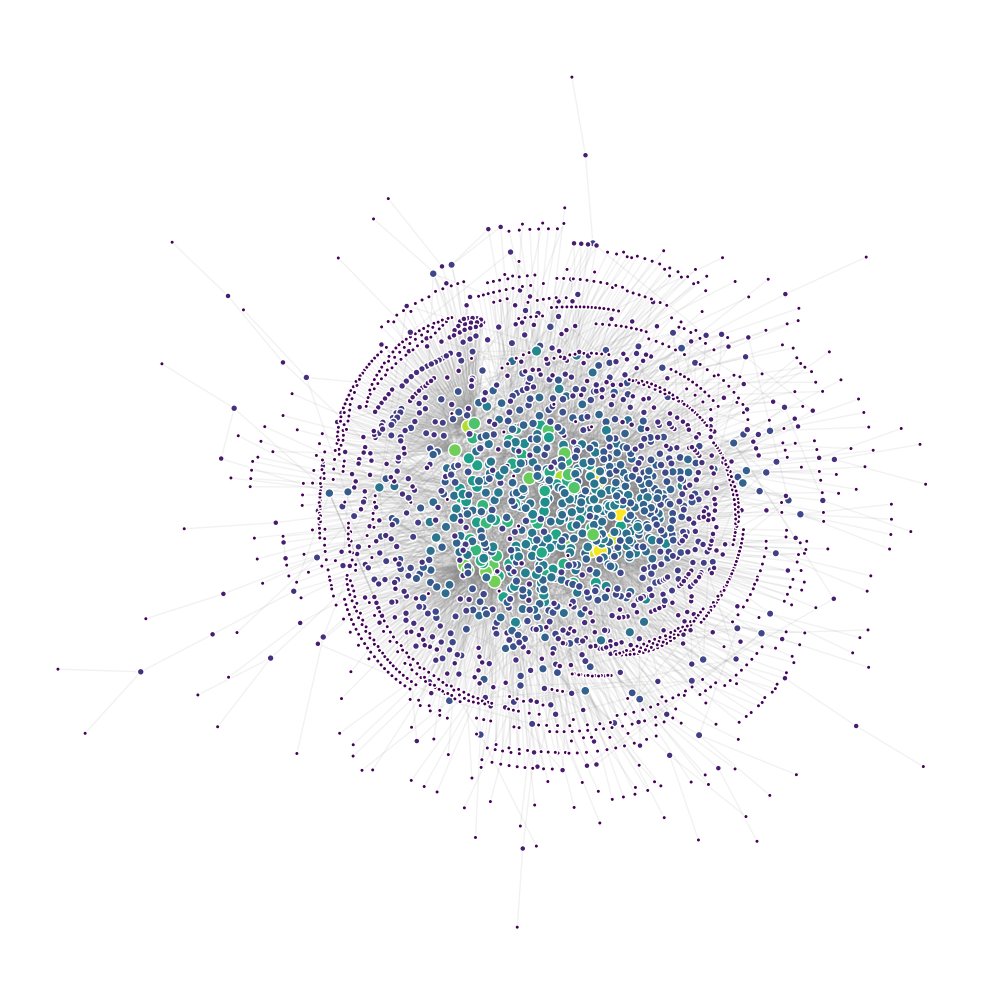

Preparing node pairs...
Commencing edge generation...


100%|██████████| 32/32 [00:00<00:00, 36.95it/s]


Refining network structure...
Calculating betweenness...
Done.
Calculating node positions...
Done.


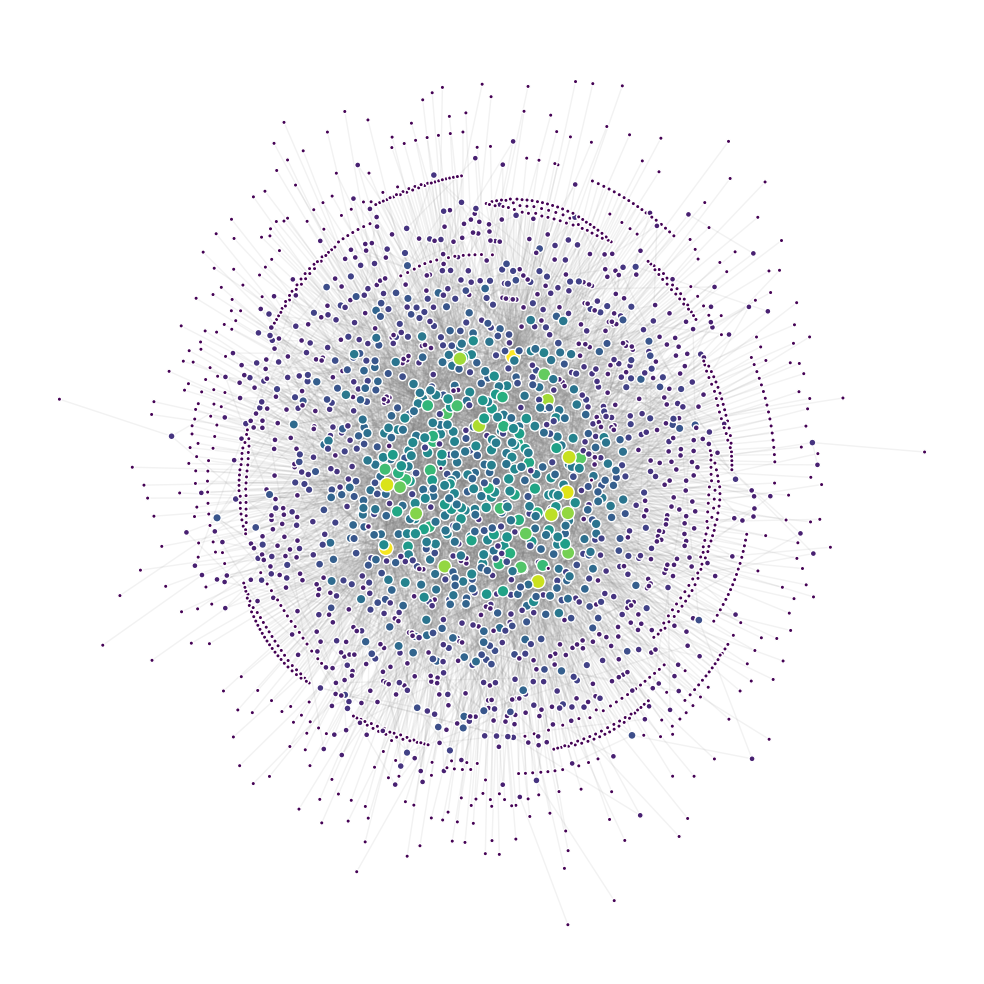

Preparing node pairs...
Commencing edge generation...


100%|██████████| 32/32 [00:00<00:00, 36.92it/s]


Refining network structure...
Calculating betweenness...
Done.
Calculating node positions...
Done.


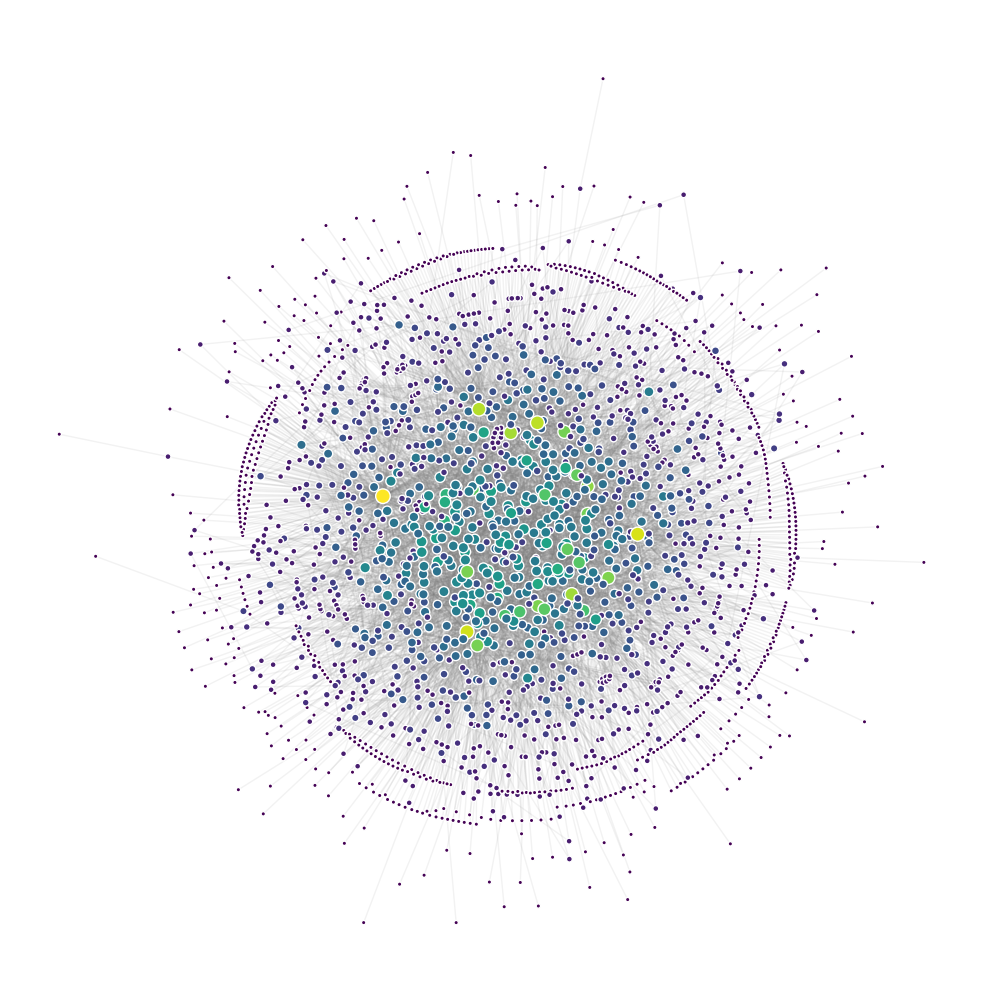

Preparing node pairs...
Commencing edge generation...


100%|██████████| 32/32 [00:00<00:00, 37.21it/s]


Refining network structure...
Calculating betweenness...
Done.
Calculating node positions...
Done.


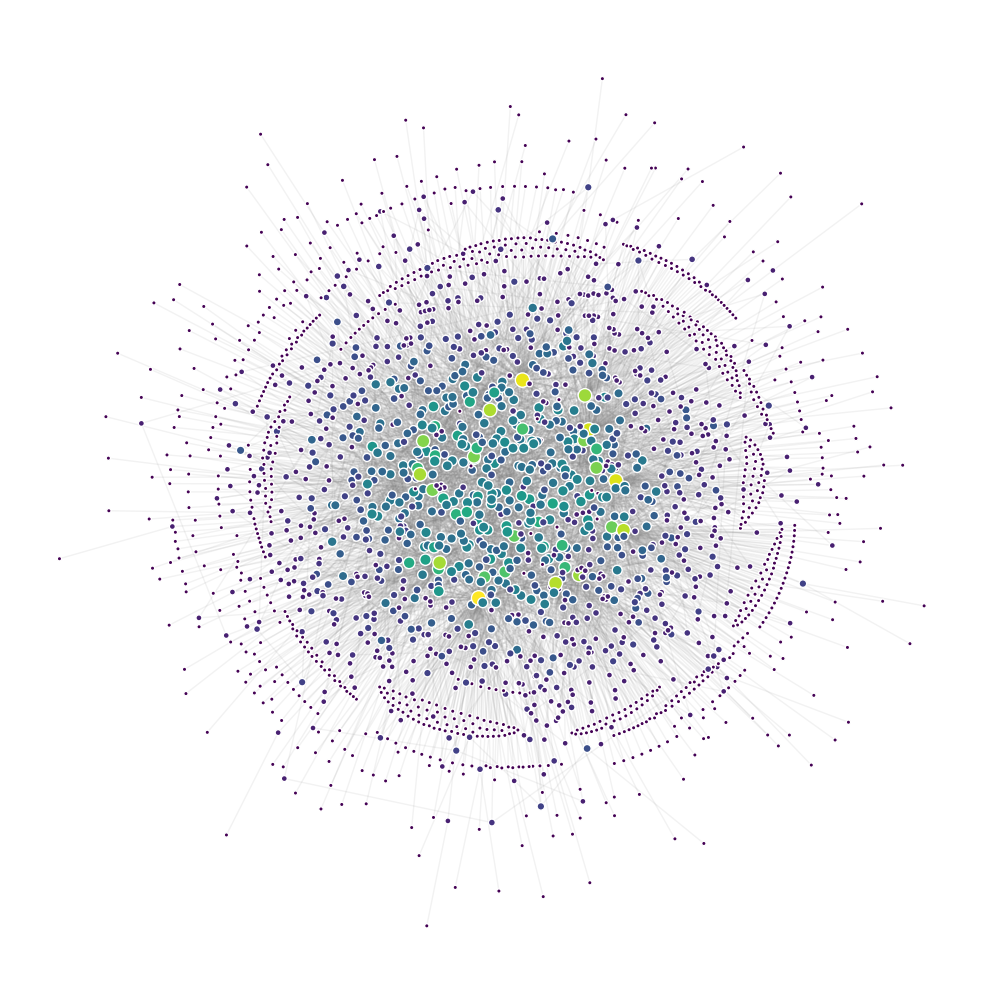

In [39]:
mfnf.generate_variants(
    plot_options = {
        'layout_func': nx.kamada_kawai_layout,
        'figsize': (10,10),
        'filename':  "figures/human_proteins_network_figeys_variants.pdf"
    },
    filename = "variant_networks/human_proteins_network_figeys_variants.graphml"
)

---

# Comparison with Benson et al's Method

In [8]:
k2 = np.log(len(G))/np.log(2)
print(k2)
k3 = np.log(len(G))/np.log(3)
print(k3)

11.128638812852598
7.021389343778846


In [9]:
mfnf = MultifractalNetworkFitter(
    G,                                   
    motifs = [
        {'name': 'four_star', 'matrix': np.array([[0, 1, 1, 1, 1],[1, 0, 0, 0, 0],[1, 0, 0, 0, 0],[1, 0, 0, 0, 0],[1, 0, 0, 0, 0]])},
    ],
    sampling_ratios = {
        3: 0.01,
        4: 0.0001,
        5: 0.000001,
    },
    motif_analyzer_args = {'exact': True, 'bootstrap_iters': None, 'ci': None},
    population_size = 6000,
    weights = {
        'rho':0,
        'deg_nn':0,
        'motifs':1
    }
)

Measuring graph properties...
Degree distribution...
Degree correlations...
Motifs...
Checking compatibility with 1 user-provided motifs.
Adding custom motif 'four_star'.
Counting motifs of size 3... grab a tea or watch a movie, this might take a while.
Motif counting finished in 0:00:00.723999
Counting motifs of size 4... grab a tea or watch a movie, this might take a while.
Motif counting finished in 0:01:00.906250
Counting motifs of size 5... grab a tea or watch a movie, this might take a while.
Motif counting finished in 1:36:32.724660


In [10]:
mfnf.find_P_l(2,11,one_shot = True)
P2 = mfnf.P
L2 = mfnf.l

Energy: 1.2140050767640147
KL-divergence: 0.31274578222821753
KLD augumented energy: 1.2140050767640147


In [11]:
mfnf.find_P_l(3,7,one_shot = True)
P3 = mfnf.P
L3 = mfnf.l

Energy: 0.9303894721932864
KL-divergence: 0.22839256285402854
KLD augumented energy: 0.9303894721932864


In [12]:
mfnf_no_fit = MultifractalNetworkFitter(
    G,                                   
    motifs = [
        {'name': 'four_chain', 'matrix': np.array([[0, 1, 0, 0],[1, 0, 1, 0],[0, 1, 0, 1],[0, 0, 1, 0]])},
        {'name': 'three_loop_out', 'matrix': np.array([[0, 1, 1, 1],[1, 0, 1, 0],[1, 1, 0, 0],[1, 0, 0, 0]])},
        {'name': 'four_loop', 'matrix': np.array([[0, 1, 0, 1],[1, 0, 1, 0],[0, 1, 0, 1],[1, 0, 1, 0]])},
        {'name': 'four_semi_clique', 'matrix': np.array([[0, 1, 1, 1],[1, 0, 0, 1],[1, 0, 0, 1],[1, 1, 1, 0]])},
    ],
    sampling_ratios = {
        3: 0.01,
        4: 0.0001
    },
    motif_analyzer_args = {'exact': True, 'bootstrap_iters': None, 'ci': None},
    population_size = 100,
    weights = {
        'rho':9,
        'deg_nn':9,
        'motifs':1,
        'edge':9,
        'triangle':9
    }
)

Measuring graph properties...
Degree distribution...
Degree correlations...
Motifs...
Checking compatibility with 4 user-provided motifs.
Adding custom motif 'four_chain'.
Adding custom motif 'three_loop_out'.
Adding custom motif 'four_loop'.
Adding custom motif 'four_semi_clique'.
Counting motifs of size 3... grab a tea or watch a movie, this might take a while.
Motif counting finished in 0:00:00.714014
Counting motifs of size 4... grab a tea or watch a movie, this might take a while.
Motif counting finished in 0:01:03.210526


In [40]:
mfnf_no_fit.P = P2
mfnf_no_fit.l = L2
mfnf_no_fit.k = 11
mfnf_no_fit._calculate_metrics()
mfnf_no_fit.motifs

In [ ]:
with open('./test_networks/human_proteins_network_figeys_benson_2_mfnf.pkl', 'wb') as f:
    pickle.dump(mfnf_no_fit, f)

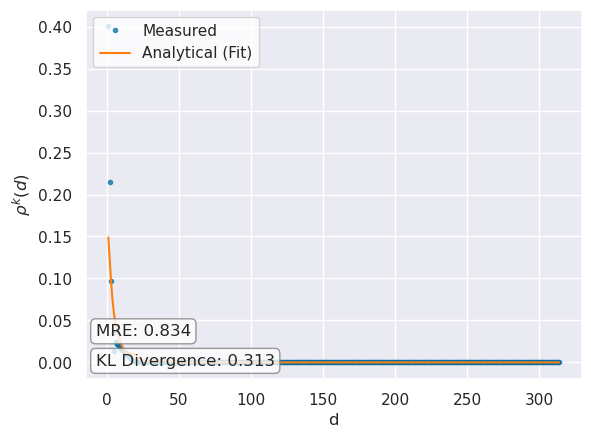

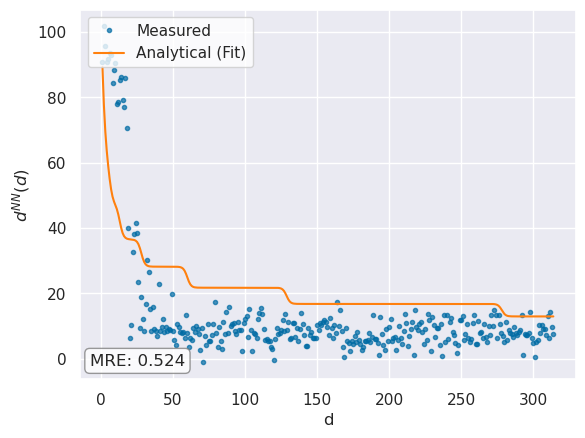

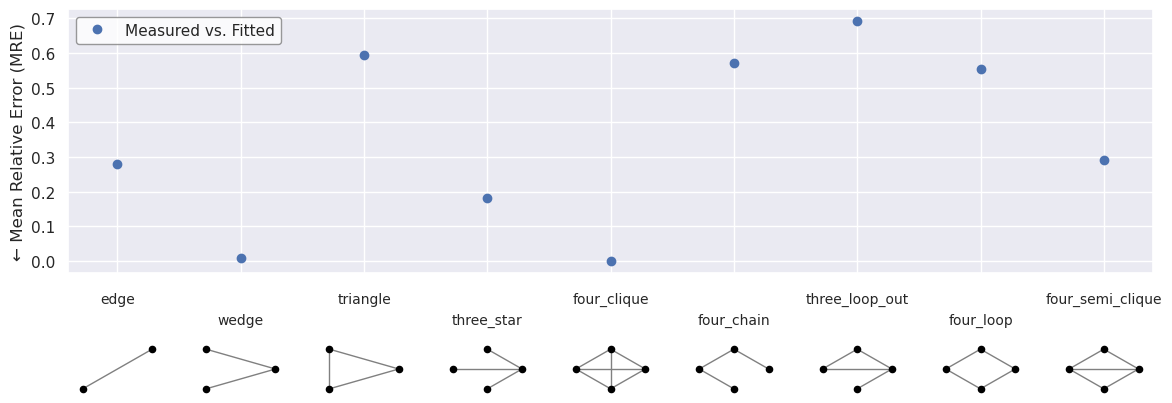

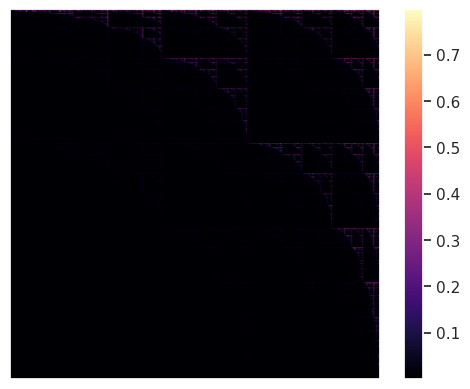

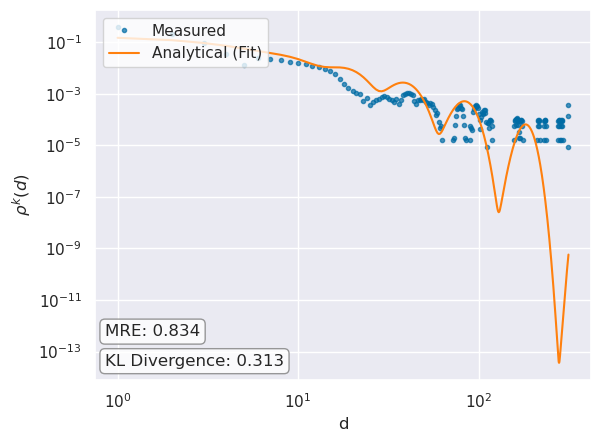

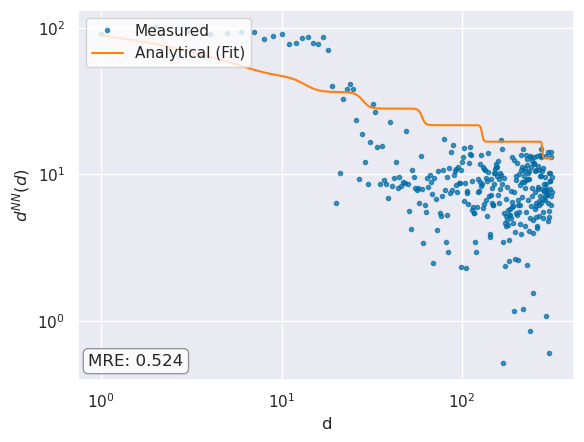

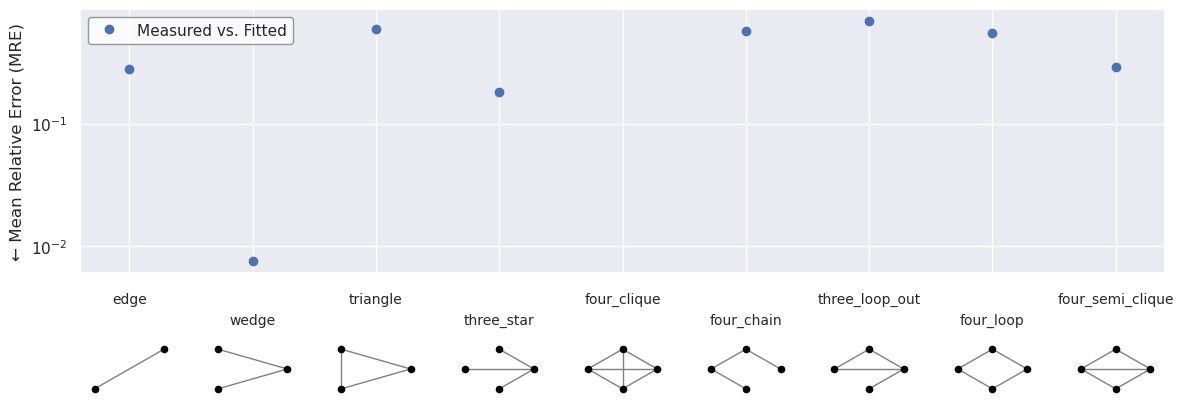

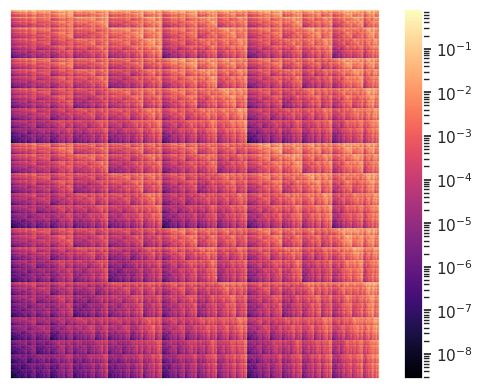

In [41]:
mfnf_no_fit.plot_P_l_result(
    log_scale = False,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    filename = "figures/human_proteins_network_figeys_benson_2_plot.pdf"
)
mfnf_no_fit.plot_P_l_result(
    log_scale = True,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    filename = "figures/human_proteins_network_figeys_benson_2_log_plot.pdf"
)

In [42]:
mfnf_no_fit.P = P3
mfnf_no_fit.l = L3
mfnf_no_fit.k = 7
mfnf_no_fit._calculate_metrics()
mfnf_no_fit.motifs

In [ ]:
with open('./test_networks/human_proteins_network_figeys_benson_3_mfnf.pkl', 'wb') as f:
    pickle.dump(mfnf_no_fit, f)

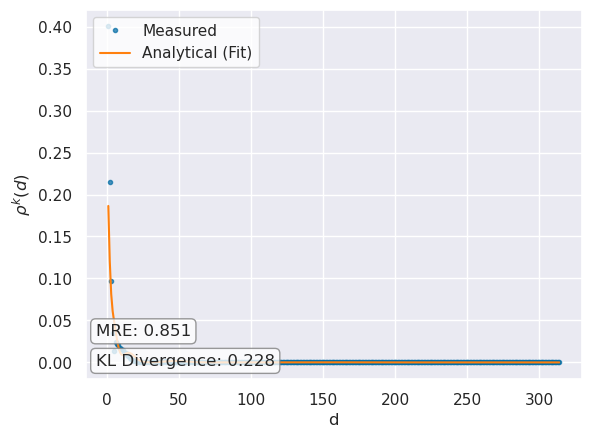

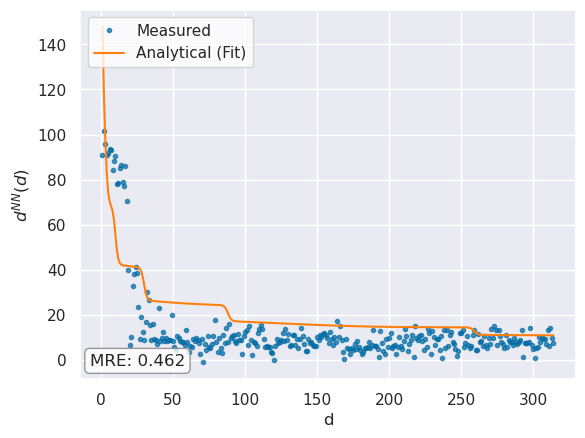

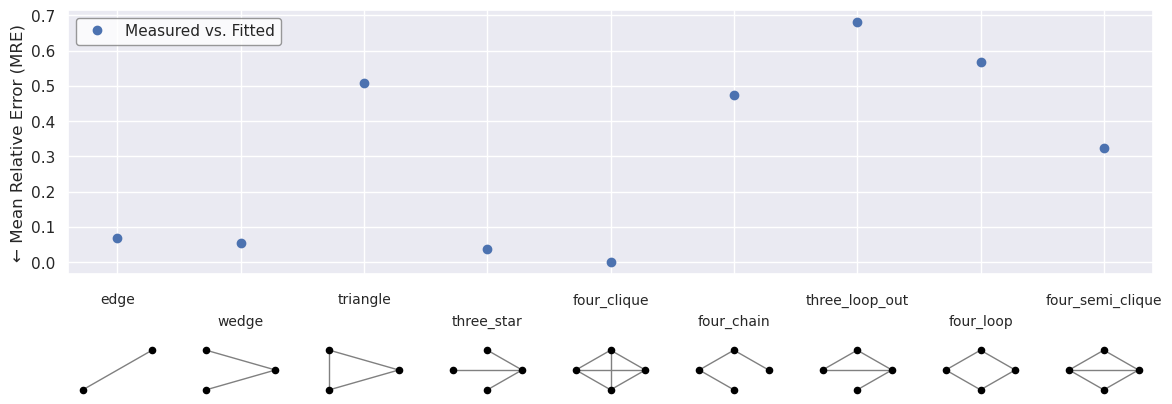

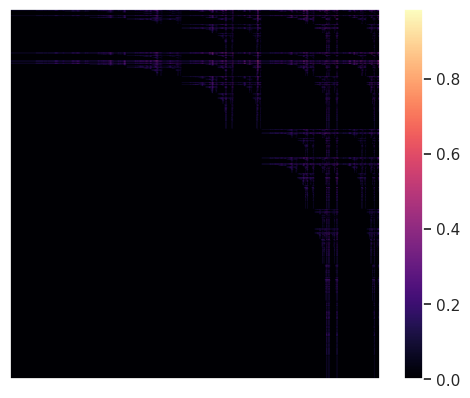

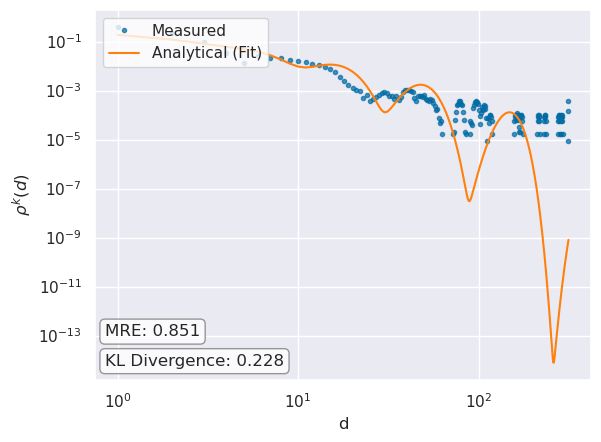

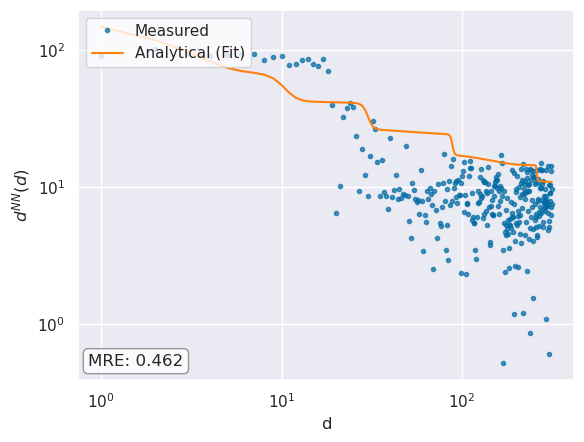

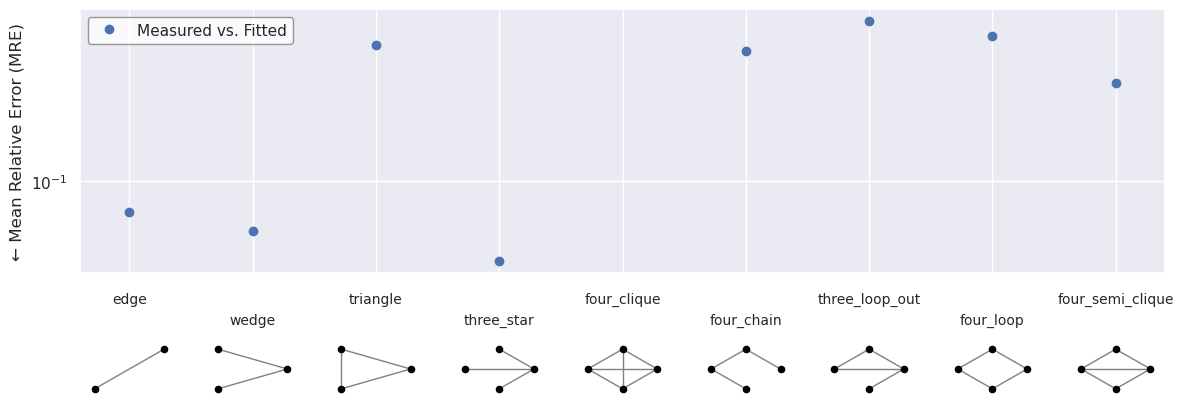

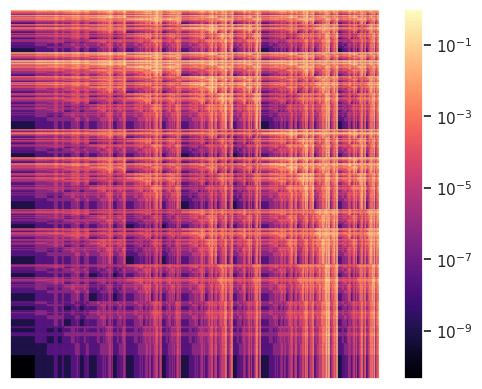

In [43]:
mfnf_no_fit.plot_P_l_result(
    log_scale = False,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    filename = "figures/human_proteins_network_figeys_benson_3_plot.pdf"
)
mfnf_no_fit.plot_P_l_result(
    log_scale = True,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    filename = "figures/human_proteins_network_figeys_3_log_plot.pdf"
)